## Task 1 — Prior Distribution Analysis

**Data generation**

Run the following command from the repository root:

```bash
flashsim generate -n 50000 --seed 5 -o data/t2_full.h5
```

**Environment**

Use the Python environment configured according to the project's installation instructions.

**Reproducibility**

* Number of simulated events: 50,000
* Random seed: 5
* Simulation preset: full (default)
* Data file: `data/t2_full.h5`

The notebook assumes that the current working directory is the repository root.


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from prob_reco_sbi.flash import load

data = load("data/t2_full.h5") #load data

x = data.truth.x
y = data.truth.y
E = data.truth.energy
t0 = data.truth.t0   #extract event parameters

print("Number of events:", len(x))  # Check the number of events

Number of events: 50000


In [12]:
r0 = np.sqrt(x**2 + y**2)
r0_squared = r0**2

print("First five radii:", r0[:5])
print("Maximum radius:", r0.max())

First five radii: [0.6349161  0.86809665 0.1784311  0.1440533  0.35112447]
Maximum radius: 0.9999992


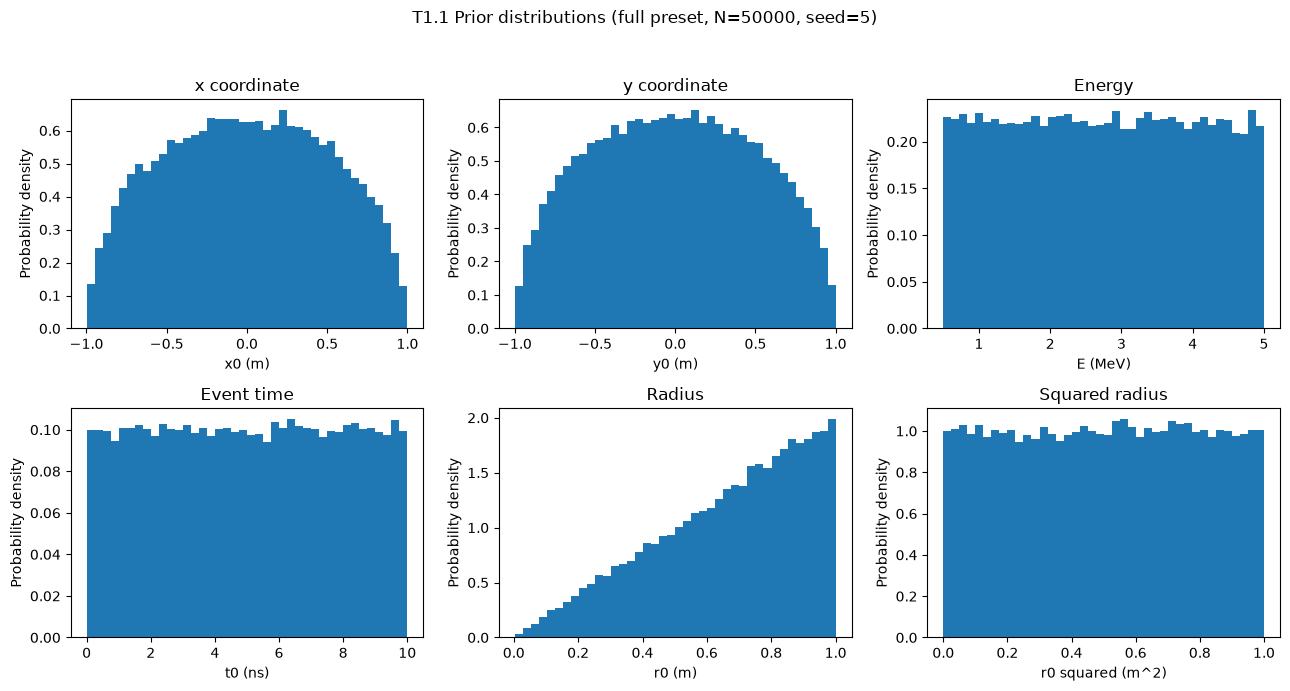

In [10]:
# T1.1: Histograms of prior parameters
fig, axes = plt.subplots(2, 3, figsize=(13, 7)) 
variables = [
    (x, "x coordinate", "x0 (m)"),
    (y, "y coordinate", "y0 (m)"),
    (E, "Energy", "E (MeV)"),
    (t0, "Event time", "t0 (ns)"),
    (r0, "Radius", "r0 (m)"),
    (r0_squared, "Squared radius", "r0 squared (m^2)")
]

for ax, (values, title, xlabel) in zip(axes.flat, variables):  #axes.flat会让我们按顺序遍历这 6 个绘图区域
    ax.hist(values, bins=40, density=True) #绘制归一化的直方图
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability density")

fig.suptitle("T1.1 Prior distributions (full preset, N=50000, seed=5)")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("T1.1_prior_histograms.png", dpi=200)
plt.show()

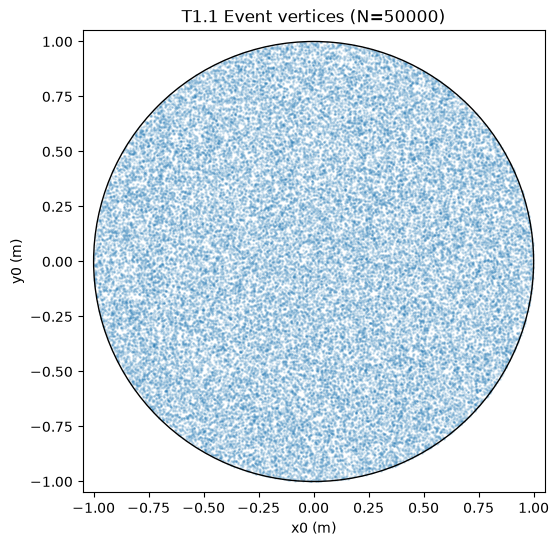

In [13]:
# T1.1: 2D distribution of event vertices
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x, y, s=1, alpha=0.15)

# Draw detector boundary
circle = plt.Circle((0, 0), 1.0, fill=False)
ax.add_patch(circle)

ax.set_xlabel("x0 (m)")
ax.set_ylabel("y0 (m)")
ax.set_title("T1.1 Event vertices (N=50000)")

ax.set_aspect("equal") #让 x 轴和 y 轴的单位长度在图上保持一致
ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-1.05, 1.05)

plt.savefig("T1.1_vertices.png", dpi=200)
plt.show()